In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Carga y exploración del primer DataFrame que contiene company_name y trips_amount

In [2]:
df_companias= pd.read_csv('/datasets/project_sql_result_01.csv')
print(df_companias.info())
df_companias.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [3]:
df_companias.duplicated().sum()

0

In [4]:
df_companias['company_name'].duplicated().sum()

0

## Observaciones:

Respecto al primer df, que nombre df_companias, los tipos de datos son correctos porque habla de número de viajes, y aquí no se puentan en decimales porque no puede existir medio viaje o un cuarto de viaje. Para ambas columnas hay 64 celdas no nulas.  

# Carga y exploración del segundo DataFrame que contiene dropoff_location_name y average_trips

In [5]:
df_barrios= pd.read_csv('/datasets/project_sql_result_04.csv')
print(df_barrios.info())
df_barrios.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB
None


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


In [6]:
df_barrios.duplicated().sum()

0

In [7]:
df_barrios['dropoff_location_name'].duplicated().sum()

0

## Observaciones:
Respecto al segundo df, que nombre df_barrios, los tipos son los ideales para cuantificar la información porque averange indica el promedio de viajes. Para ambas columnas hay 94 celdas no nulas.

# Identificar los 10 principales barrios en términos de finalización de viajes

In [8]:

top10_barrios = df_barrios.sort_values(by='average_trips', ascending=False). head(10)
print(top10_barrios)


  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


## Observaciones:

Usé la columna average_trips porque tiene el promedio de viajes que terminan en cada barrio. El barrio con mayor promedio de viajes finalizados es Loop con 10727.46; mientras que el último es Sheffield & DePaul con 1259.76.

# Gráfica de empresas de taxis y número de viajes

Para esta parte del ejercicio, usé un top 10 de las compañías con más viajes. Al ser 64, el gráfico sería difícil de leer y las compañías que tienen un número mínimo de viajes aportarían pocos datos a la gráfica. 

In [9]:
companias_top= df_companias.sort_values(by='trips_amount', ascending=False). head(10)
print(companias_top)

                        company_name  trips_amount
0                          Flash Cab         19558
1          Taxi Affiliation Services         11422
2                  Medallion Leasing         10367
3                         Yellow Cab          9888
4    Taxi Affiliation Service Yellow          9299
5          Chicago Carriage Cab Corp          9181
6                       City Service          8448
7                           Sun Taxi          7701
8          Star North Management LLC          7455
9  Blue Ribbon Taxi Association Inc.          5953


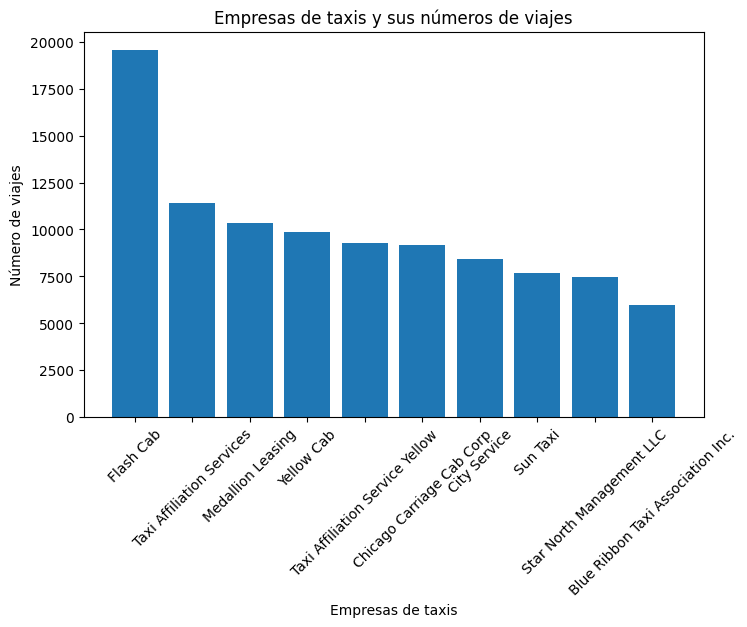

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.bar(companias_top['company_name'], companias_top['trips_amount'])
plt.title('Empresas de taxis y sus números de viajes')
plt.xlabel('Empresas de taxis')
plt.ylabel('Número de viajes')
plt.xticks(rotation=45)
plt.show()

## Observaciones:

La gráfica de empresas de taxis revela que Flash cab está por encima de las demás. Mientras las otras registran entre 7 mil 500 a 11 mil viajes, Flash Cab alcanza casi los 20 mil

# Gráfica de los 10 barrios principales por número de finalizaciones

In [11]:
top10_barrios = df_barrios.sort_values(by='average_trips', ascending=False). head(10)
print(top10_barrios)


  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


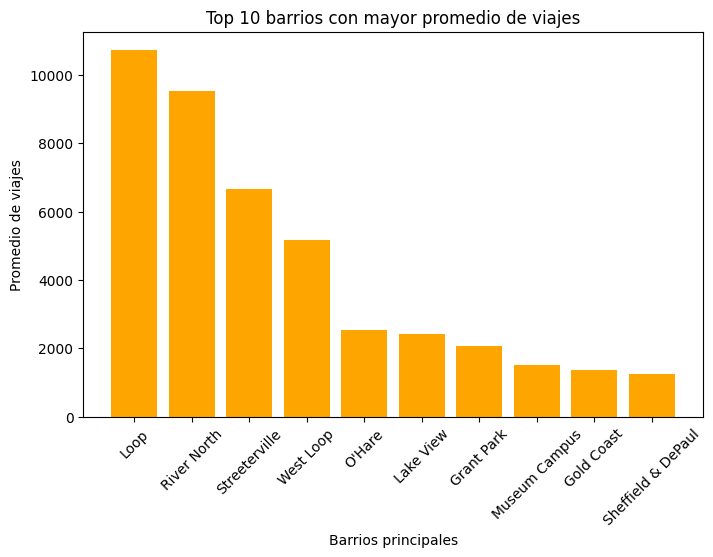

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.bar(top10_barrios['dropoff_location_name'], top10_barrios['average_trips'], color = 'orange')
plt.title('Top 10 barrios con mayor promedio de viajes')
plt.xlabel('Barrios principales')
plt.ylabel('Promedio de viajes')
plt.xticks(rotation=45)
plt.show()

## Observaciones:

En el top 10 barrios principales, la distribución promedio de viajes es un poco más equilibrada en comparación con la gráfica anterior: lideran la lista Loop (con más de 10 mil), lo sigue de cerca River North (con casi 10 mil) y en tercer lugar, Streeterville aparece con más de 6 mil. En el cuarto lugar está West Loop con casi 6 mil. En cuanto a las otras regiones, mantienen un promedio de entre 2 mil viajes y menos de 4 mil.


# Prueba de hipótesis

Antes de comenzar con la prueba de las hipótesis, revisé cuáles son los dos valores del clima para poder filtrar de acuerdo a ellos: 'Good' y 'Bad'. Despúes convertí start_ts a datatime para extraer el día sábado. Aunque el .value_counts haya revelado que la lista es de sábados, decidí filtrar bajo la condición de los sábados solo como un ejercicio de dos condiciones en un filtrado.

In [13]:
df_duracion= pd.read_csv('/datasets/project_sql_result_07.csv')
df_duracion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB


In [14]:
df_duracion['weather_conditions'].unique()

array(['Good', 'Bad'], dtype=object)

In [15]:
df_duracion['duration_seconds'].head()

0    2410.0
1    1920.0
2    1543.0
3    2512.0
4    1440.0
Name: duration_seconds, dtype: float64

In [16]:
df_duracion['start_ts'] = pd.to_datetime(df_duracion['start_ts'])
df_duracion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1068 non-null   datetime64[ns]
 1   weather_conditions  1068 non-null   object        
 2   duration_seconds    1068 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 25.2+ KB


In [17]:
df_duracion['start_ts'].dt.day_name().value_counts()

Saturday    1068
Name: start_ts, dtype: int64

In [18]:
from scipy import stats
import scipy.stats as st

#H0: μ(duration_seconds cuando el clima es bueno) = μ(duration_seconds  cuando el clima es malo)
#H1: μ(duration_seconds cuando el clima es bueno) ≠ μ(duration_seconds  cuando el clima es malo)

alpha = 0.05


mal_clima_duracion = df_duracion[(df_duracion['weather_conditions'] == 'Bad') & (df_duracion['start_ts'].dt.day_name() == 'Saturday')] ['duration_seconds']

duracion_buen_clima = df_duracion[(df_duracion['weather_conditions'] == 'Good') & (df_duracion['start_ts'].dt.day_name()== 'Saturday')] ['duration_seconds']

print('varianza del mal clima:', mal_clima_duracion.var())
print('varianza del buen clima:', duracion_buen_clima.var())

print('Promedio de duración de los viajes los sábados lluviosos:', mal_clima_duracion.mean())
print('Promedio de duración de los viajes cuando hay buen clima:', duracion_buen_clima.mean())

hip_duracion = st.ttest_ind(mal_clima_duracion, duracion_buen_clima, equal_var=True)

p_valor = hip_duracion.pvalue 

if p_valor  < alpha:
    print("Rechazamos la hipótesis nula (H0): Cambia el promedio de la duración de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare los sábados lluviosos")
else:
    print('Se mantiene la hipótesis nula (H0): No hay evidencia respecto al cambio de la duración promedio de viajes.')
print(p_valor)

varianza del mal clima: 520294.086002483
varianza del buen clima: 576382.009689509
Promedio de duración de los viajes los sábados lluviosos: 2427.2055555555557
Promedio de duración de los viajes cuando hay buen clima: 1999.6756756756756
Rechazamos la hipótesis nula (H0): Cambia el promedio de la duración de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare los sábados lluviosos
6.517970327099473e-12


# Explicación sobre la prueba de hipótesis

La prueba de hipótesis muestra que hay un cambio en el promedio de la duración de los viajes cuando llueve. El promedio sube de ~2000 segundos (buen clima) a ~2427 segundos (lluvia), así que es un hecho: los viajes tardan más cuando llueve.

En la hipótesis nula, formulé una comparación en la que el clima no importa y la duración de los viajes es igual tanto para los sábados lluviosos como para los que tienen un buen clima.

Respecto a la hipótesis alternativa (H1), introduje la comparación desigual en la que los sábados lluviosos cambian el promedio de la duración de  los viajes. 

El criterio que usé para probar las  hipótesis se basó en las de carácter independiente porque no se trata del mismo viaje medido dos veces. En otras palabras, no hay emparejamiento entre las observaciones de un grupo y las del otro.

Por último, decidí usar True en la varianza porque al calcular la de ambos grupos (buen clima y mal clima) resultó que la diferencia era pequeña.